# LAB 04 — Text Classification
**Corpus:** 10.000 IMDb reviews có nhãn; seed 2026. **Task:** positive / negative sentiment.

In [1]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
from sklearn.dummy import DummyClassifier
from preprocessing import prepare_dataset, tokenize, clean_text, SEED
from classification import (LABELS, fit_tfidf, fit_embeddings, transform, scores,
    result_row, evaluate_test, feature_contributions, snippet, select_examples)
ROOT = Path.cwd()
plt.rcParams.update({"figure.dpi":110, "axes.grid":False})
pd.set_option("display.max_colwidth",120)
def table(rows):
    df=rows if isinstance(rows,pd.DataFrame) else pd.DataFrame(rows)
    print(df.round(4).to_string(index=False,max_rows=None,max_cols=None))
def note(text):
    print("\nNhận xét tham khảo: "+text)
models={}

## 11. Experiment 1 — Dataset inspection
Nguồn: [Large Movie Review Dataset, Stanford](https://ai.stanford.edu/~amaas/data/sentiment/).
Đọc 50.000 review có nhãn để kiểm tra chất lượng, loại duplicate theo normalized text và bỏ nhóm nhãn xung đột trước sampling.
Lấy 8.000 review từ official train rồi chia 6.000 train / 2.000 validation; lấy 2.000 review từ official test.
Mỗi split cân bằng hai nhãn; không dùng phần unsupervised. Báo cáo cả số liệu nguồn và subset.

Rebuilding subset: cached seed=42, requested seed=2026


                               Check                                                                    Value
                          source_url          https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz
                                seed                                                                     2026
              source_labeled_samples                                                                    50000
                      source_classes                                                                        2
                 source_missing_text                                                                        0
               source_missing_labels                                                                        0
       source_exact_duplicate_excess                                                                      418
  source_normalized_duplicate_excess                                                                      422
      sour

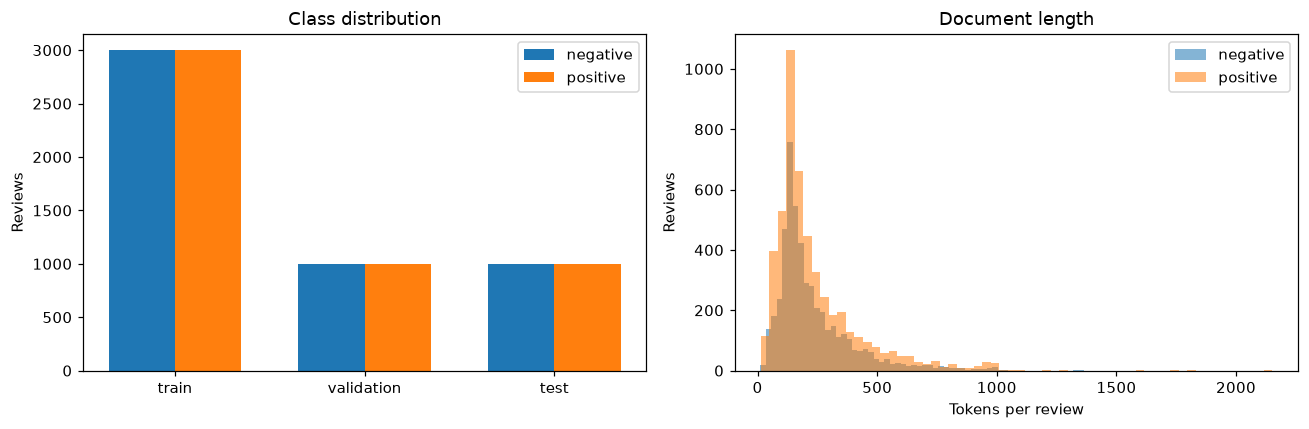


Nhận xét tham khảo: Mỗi split có 50% positive và 50% negative nên subset không có class imbalance. Phân phối chiều dài và duplicate được kiểm tra trước khi train; balanced sampling không đại diện mọi dữ liệu thực tế.


In [2]:
data,audit=prepare_dataset(ROOT)
train=data[data.split.eq("train")].reset_index(drop=True)
validation=data[data.split.eq("validation")].reset_index(drop=True)
test=data[data.split.eq("test")].reset_index(drop=True)
table([{"Check":k,"Value":v} for k,v in audit.items() if not isinstance(v,dict)])
distribution=data.groupby(["split","label"]).size().rename("Count").reset_index()
distribution["Class"]=distribution.label.map(LABELS)
distribution["Percentage"]=distribution["Count"]/distribution.groupby("split")["Count"].transform("sum")*100
table(distribution[["split","Class","Count","Percentage"]])
table(data.groupby("split").token_count.describe(percentiles=[.25,.5,.75,.95]).reset_index())
print("\nVí dụ dữ liệu:")
for label in [0,1]:
    row=train[train.label.eq(label)].iloc[0]
    print(LABELS[label]+": "+snippet(row.text,[],300))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for label in [0,1]:
    values=[int((data.split.eq(s)&data.label.eq(label)).sum()) for s in ["train","validation","test"]]
    axes[0].bar(np.arange(3)+(label-.5)*.35,values,width=.35,label=LABELS[label])
axes[0].set_xticks(range(3),["train","validation","test"])
axes[0].set_ylabel("Reviews"); axes[0].set_title("Class distribution");axes[0].legend()
for label in [0,1]:
    axes[1].hist(data[data.label.eq(label)].token_count,bins=60,alpha=.55,label=LABELS[label])
axes[1].set_xlabel("Tokens per review");axes[1].set_ylabel("Reviews")
axes[1].set_title("Document length");axes[1].legend()
plt.tight_layout();plt.show()
note("Mỗi split có 50% positive và 50% negative nên subset không có class imbalance. "
     "Phân phối chiều dài và duplicate được kiểm tra trước khi train; balanced sampling không đại diện mọi dữ liệu thực tế.")

## 12. Data leakage — bắt buộc
Chỉ train được dùng để fit vocabulary, IDF, Word2Vec và trọng số classifier.
Validation chọn cấu hình theo macro-F1; test chỉ mở sau khi đã khóa lựa chọn.
Normalize HTML/lowercase/negation là phép biến đổi không học tham số; dedup phục vụ ngăn cùng văn bản xuất hiện ở nhiều split.
Không gọi fit trên validation/test, không dùng C4 hay Word2Vec train trên toàn bộ IMDb.

Fit TF-IDF trước split gây leakage vì vocabulary/IDF chứa thông tin thống kê của văn bản test.
Loại exact/normalized duplicate không loại được mọi near-duplicate hoặc overlap chủ đề.

### Vì sao đây là data leakage?
Nếu fit TF-IDF trên toàn bộ dataset trước khi split, vocabulary đã biết các từ xuất hiện trong test,
và IDF đã sử dụng số tài liệu chứa mỗi từ ở cả train lẫn test.
Ví dụ IDF dạng log((1+N)/(1+df))+1: cả N và df đều bị ảnh hưởng bởi tài liệu test.

Như vậy thông tin của tập đánh giá đã đi vào feature vectors dùng để huấn luyện,
dù chưa dùng nhãn test. Test không còn hoàn toàn độc lập với quá trình học;
kết quả có thể bị thiên lệch và không phản ánh đúng khả năng xử lý dữ liệu chưa từng thấy.

Cách đúng: split trước, fit vocabulary/IDF chỉ trên train, sau đó chỉ transform validation/test.
Word2Vec và các bước preprocessing có học tham số cũng phải tuân theo nguyên tắc này.


In [3]:
overlap=[]
for a,b in [("train","validation"),("train","test"),("validation","test")]:
    left=set(data[data.split.eq(a)].text_hash)
    right=set(data[data.split.eq(b)].text_hash)
    overlap.append({"Split A":a,"Split B":b,"Shared normalized hashes":len(left&right)})
table(overlap)
print("Official nguồn train/validation:",sorted(set(train.official_split)|set(validation.official_split)))
print("Official nguồn test:",sorted(set(test.official_split)))
print("Train / validation / test:",len(train),len(validation),len(test))

   Split A    Split B  Shared normalized hashes
     train validation                         0
     train       test                         0
validation       test                         0
Official nguồn train/validation: ['train']
Official nguồn test: ['test']
Train / validation / test: 6000 2000 2000


## 13. Core implementation
Code được chia vào preprocessing.py và classification.py để notebook ngắn, dễ đọc.
TF-IDF: tokenizer giữ not/no/never, min_df=2, sublinear_tf=True, L2 normalization.
LR: liblinear, C=1, max_iter=1000, seed=2026; threshold mặc định 0.5.
Training time gồm fit representation, transform train và fit classifier; transform validation/test không tính vào training time.

## 14. Experiment 2 — Baseline
Baseline TF-IDF unigram với max_features=10.000. Precision/Recall/F1 mặc định tính cho positive; macro-F1 báo cáo thêm.

In [4]:
baseline=fit_tfidf("TF-IDF unigram 10k + LR",train,validation)
models[baseline["name"]]=baseline
table([result_row(baseline,"validation")])
note(f"Baseline validation accuracy={baseline['validation']['accuracy']:.4f}, "
     f"F1 positive={baseline['validation']['f1']:.4f}. Chưa sử dụng test để điều chỉnh model.")

 seed                   model      split representation classifier  feature_count  vocabulary_size  max_features ngrams stopwords   C  train_samples  validation_samples  test_samples  feature_fit_seconds  classifier_fit_seconds  training_seconds  accuracy  precision  recall     f1  macro_f1  tn  fp  fn  tp
 2026 TF-IDF unigram 10k + LR validation         TF-IDF         LR          10000            10000         10000      1      kept 1.0           6000                2000          2000               1.5449                  0.1191             1.664    0.8745     0.8577   0.898 0.8774    0.8744 851 149 102 898

Nhận xét tham khảo: Baseline validation accuracy=0.8745, F1 positive=0.8774. Chưa sử dụng test để điều chỉnh model.


## 15. Experiment 3 — Representation comparison
Word2Vec CBOW: 100 chiều, window=5, min_count=2, epochs=10, negative=5, workers=1, seed=2026, hash SHA256, fixed window.
Chỉ train reviews được dùng học embeddings, tách câu trước tạo context. Review được biểu diễn bằng trung bình các vector in-vocabulary rồi L2 normalize.
Review không có từ known được gán vector 0 và được báo cáo. TF-IDF và Avg Word2Vec dùng cùng LR và C=1.
Thêm TF-IDF + Linear SVM làm model C.

Training Word2Vec on TRAIN reviews only...


Word2Vec training complete.


 seed                    model      split representation classifier  feature_count  vocabulary_size  max_features ngrams stopwords   C  train_samples  validation_samples  test_samples  feature_fit_seconds  classifier_fit_seconds  training_seconds  accuracy  precision  recall     f1  macro_f1  tn  fp  fn  tp
 2026  TF-IDF unigram 10k + LR validation         TF-IDF         LR          10000            10000       10000.0      1      kept 1.0           6000                2000          2000               1.5449                  0.1191            1.6640    0.8745     0.8577   0.898 0.8774    0.8744 851 149 102 898
 2026        Avg Word2Vec + LR validation   Avg Word2Vec         LR            100            26416           NaN    N/A      kept 1.0           6000                2000          2000              21.9739                  0.0899           22.0638    0.8080     0.8050   0.813 0.8090    0.8080 803 197 187 813
 2026 TF-IDF unigram 10k + SVM validation         TF-IDF Linear SVM      

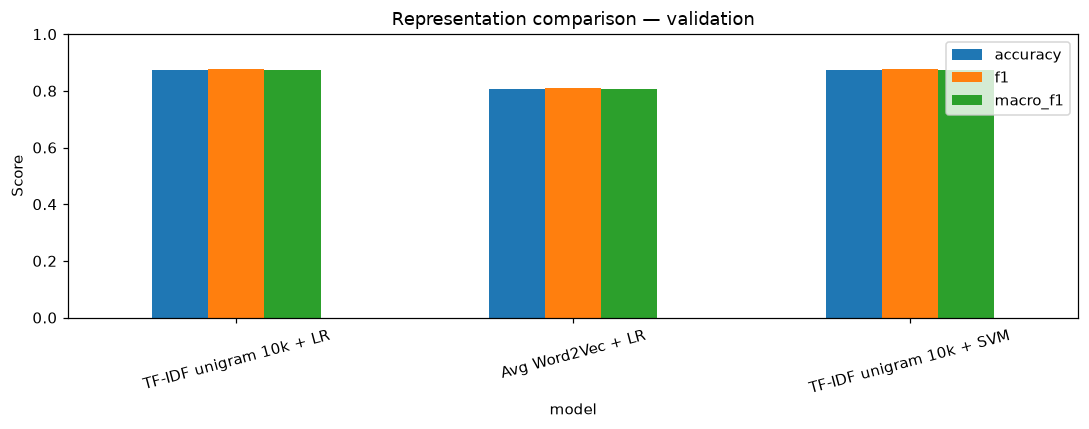

In [5]:
print("Training Word2Vec on TRAIN reviews only...",flush=True)
embedding=fit_embeddings(train,validation)
models[embedding["name"]]=embedding
print("Word2Vec training complete.",flush=True)
svm=fit_tfidf("TF-IDF unigram 10k + SVM",train,validation,svm=True)
models[svm["name"]]=svm
comparison=pd.DataFrame([result_row(m,"validation") for m in [baseline,embedding,svm]])
table(comparison)
coverage_rows=[]
for split,cov,x in [("train",embedding["train_coverage"],embedding["x_train"]),
                    ("validation",embedding["validation_coverage"],embedding["x_validation"])]:
    coverage_rows.append({"split":split,"mean known-token fraction":np.mean(cov),
                         "zero-vector reviews":int(np.all(x==0,axis=1).sum())})
table(coverage_rows)
print("Word2Vec training vocabulary:",len(embedding["wv"].wv))
comparison.set_index("model")[["accuracy","f1","macro_f1"]].plot.bar(figsize=(10,4),ylim=(0,1),rot=15)
plt.title("Representation comparison — validation");plt.ylabel("Score")
plt.tight_layout();plt.show()

## 16. Vì sao representation tạo kết quả khác nhau?
TF-IDF giữ trọng số các từ/phrase đặc trưng; Avg Word2Vec tổng hợp semantic context và có thể làm loãng từ quyết định sentiment.
Static vectors có thể đặt từ trái nghĩa gần nhau khi xuất hiện trong ngữ cảnh tương tự. Cả unigram TF-IDF lẫn trung bình Word2Vec đều mất thứ tự.
Kết quả này còn phụ thuộc vocabulary, min_count, dữ liệu train và regularization; không đủ để kết luận một representation luôn tốt hơn.

### Nhận xét từ lần chạy seed 2026
TF-IDF baseline validation macro-F1=0.8744; Avg Word2Vec=0.8080.
Test F1 positive tương ứng 0.8751 và 0.7952.
Trong cấu hình này lexical features phù hợp sentiment hơn trung bình vectors học từ 6.000 review,
nhưng chưa đủ kết luận TF-IDF luôn tốt hơn các loại embeddings khác.


In [6]:
a,b=baseline["validation"],embedding["validation"]
note(f"TF-IDF validation macro-F1={a['macro_f1']:.4f}; Avg Word2Vec={b['macro_f1']:.4f}; "
     f"chênh lệch TF-IDF trừ Avg={a['macro_f1']-b['macro_f1']:+.4f}. "
     "Dùng probe negation và feature contributions bên dưới để kiểm tra giả thuyết về tín hiệu lexical.")


Nhận xét tham khảo: TF-IDF validation macro-F1=0.8744; Avg Word2Vec=0.8080; chênh lệch TF-IDF trừ Avg=+0.0664. Dùng probe negation và feature contributions bên dưới để kiểm tra giả thuyết về tín hiệu lexical.


## 17. Experiment 4 — Word order và negation
S1='this movie is good'; S2='this movie is not good'.
Thêm S3='good is this movie' có cùng multiset từ với S1 để phân biệt mất word order với việc thêm not.
Đây là probe định tính, không phải test set riêng. Xác suất đổi khi thêm not không chứng minh model hiểu phạm vi phủ định.

### Nhận xét từ probe seed 2026
Baseline TF-IDF có P(positive)=0,4894 cho S1 và 0,3006 cho S2, nên đoán negative cả hai.
Avg Word2Vec có P(positive)=0,6509 cho S1 và 0,4647 cho S2, tương ứng positive/negative.
S1 và S3 cho cùng prediction vì cùng multiset từ. Probe cho thấy thêm not thay đổi điểm số,
nhưng dự đoán đúng một câu không chứng minh model hiểu scope; baseline còn bỏ sót câu good ngắn trong ví dụ này.


In [7]:
probes=["this movie is good","this movie is not good","good is this movie"]
probe_rows=[]
for m in [baseline,embedding]:
    x=transform(m,probes)
    probabilities=m["clf"].predict_proba(x)[:,1]
    dense=x.toarray() if sparse.issparse(x) else x
    for i,text in enumerate(probes):
        probe_rows.append({"Model":m["name"],"Text":text,"P(positive)":probabilities[i],
                          "Prediction":LABELS[int(probabilities[i]>=.5)]})
    for j in [1,2]:
        norm=np.linalg.norm(dense[0])*np.linalg.norm(dense[j])
        cos=float(dense[0]@dense[j]/norm) if norm else np.nan
        print(m["name"],f"S1 vs S{j+1}: cosine={cos:.6f}, L2 difference={np.linalg.norm(dense[0]-dense[j]):.8f}")
table(probe_rows)
note("S1 và S3 có cùng bag-of-words nên unigram/average cho vector giống nhau (sai số số học nhỏ). "
     "S2 thêm not làm thay đổi vector, nhưng phép cộng không biểu diễn trực tiếp quan hệ not→good.")

TF-IDF unigram 10k + LR S1 vs S2: cosine=0.924723, L2 difference=0.38801260
TF-IDF unigram 10k + LR S1 vs S3: cosine=1.000000, L2 difference=0.00000000
Avg Word2Vec + LR S1 vs S2: cosine=0.934866, L2 difference=0.36092633
Avg Word2Vec + LR S1 vs S3: cosine=1.000000, L2 difference=0.00000007
                  Model                   Text  P(positive) Prediction
TF-IDF unigram 10k + LR     this movie is good       0.4894   negative
TF-IDF unigram 10k + LR this movie is not good       0.3006   negative
TF-IDF unigram 10k + LR     good is this movie       0.4894   negative
      Avg Word2Vec + LR     this movie is good       0.6509   positive
      Avg Word2Vec + LR this movie is not good       0.4647   negative
      Avg Word2Vec + LR     good is this movie       0.6509   positive

Nhận xét tham khảo: S1 và S3 có cùng bag-of-words nên unigram/average cho vector giống nhau (sai số số học nhỏ). S2 thêm not làm thay đổi vector, nhưng phép cộng không biểu diễn trực tiếp quan hệ not→good.


## 18. Experiment 5 — n-gram features
So sánh unigram và unigram+bigram với cùng min_df=2, cùng LR, **không cap max_features** để chỉ thay ngram_range.
Baseline 10k ở mục 14 là một cấu hình riêng. Bigrams tạo feature như not good, very good và làm tăng không gian feature tiềm năng.

### Bổ sung: vocabulary size và stopwords
Đánh giá unigram max_features 5k/10k/20k; so sánh giữ/bỏ English stopwords ở cùng cap 10k.
Baseline giữ not/no/never. Ablation bỏ stopwords có thể xóa negation nên không mặc định áp dụng cho model cuối.

### Nhận xét ablation — seed 2026
- Unigram/uni+bigram không cap: 24,773/142,459 features;
  validation F1 0.8747→0.8827; training time 2.23→3.62 giây.
- Vocabulary 5k/10k/20k có validation accuracy
  0.8720/0.8745/0.8715.
  Tăng vocabulary không đảm bảo accuracy tăng; cấu hình 20k thấp hơn 10k trong lần này.
- Bỏ stopwords tăng nhẹ validation F1 0.8774→0.8785,
  dù not bị loại khỏi vocabulary. Test F1 lại thấp hơn baseline
  (0.8694 so với 0.8751).
  Không dùng test để đổi cấu hình hoặc kết luận stopword removal luôn tốt/xấu.


 seed                           model      split representation classifier  feature_count  vocabulary_size max_features ngrams stopwords   C  train_samples  validation_samples  test_samples  feature_fit_seconds  classifier_fit_seconds  training_seconds  accuracy  precision  recall     f1  macro_f1  tn  fp  fn  tp
 2026    TF-IDF unigram uncapped + LR validation         TF-IDF         LR          24773            24773         None      1      kept 1.0           6000                2000          2000               2.1001                  0.1305            2.2306    0.8715     0.8535   0.897 0.8747    0.8714 846 154 103 897
 2026 TF-IDF uni+bigram uncapped + LR validation         TF-IDF         LR         142459           142459         None    1+2      kept 1.0           6000                2000          2000               3.3552                  0.2652            3.6204    0.8795     0.8597   0.907 0.8827    0.8794 852 148  93 907
 seed                                model      split r

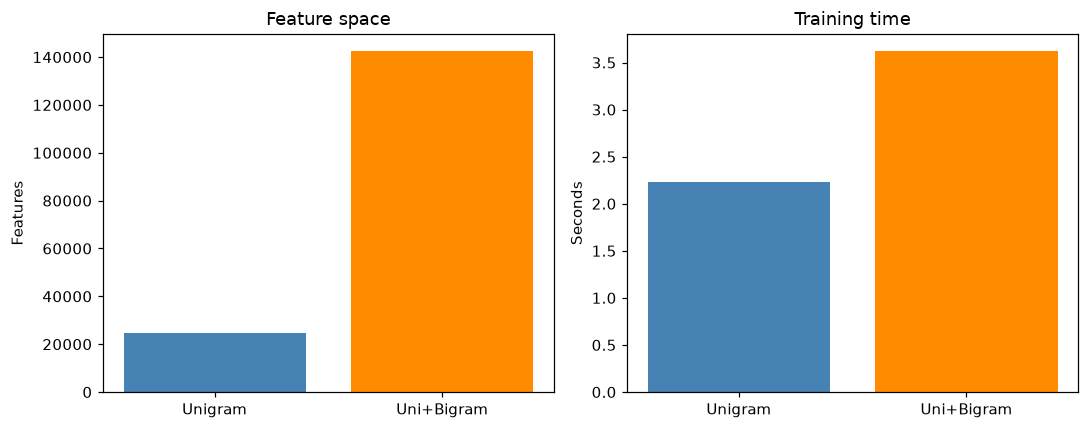

not good : feature present = True
very good : feature present = True
Stopword ablation keeps not as feature: False

Nhận xét tham khảo: N-gram validation F1: unigram=0.8747, uni+bigram=0.8827; số chiều 24773→142459. Kết quả có thể cải thiện nhờ phrase nhưng cũng tốn thêm bộ nhớ/thời gian; không đảm bảo với mọi dataset.


In [8]:
unigram_full=fit_tfidf("TF-IDF unigram uncapped + LR",train,validation,max_features=None)
bigram_full=fit_tfidf("TF-IDF uni+bigram uncapped + LR",train,validation,max_features=None,bigrams=True)
small=fit_tfidf("TF-IDF unigram 5k + LR",train,validation,max_features=5000)
large=fit_tfidf("TF-IDF unigram 20k + LR",train,validation,max_features=20000)
no_stop=fit_tfidf("TF-IDF unigram 10k no-stopwords + LR",train,validation,remove_stopwords=True)
for m in [unigram_full,bigram_full,small,large,no_stop]:
    models[m["name"]]=m
ngram_table=pd.DataFrame([result_row(m,"validation") for m in [unigram_full,bigram_full]])
table(ngram_table)
table([result_row(m,"validation") for m in [small,baseline,large,no_stop]])
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,column,title in [(axes[0],"feature_count","Feature space"),(axes[1],"training_seconds","Training time")]:
    ax.bar(["Unigram","Uni+Bigram"],ngram_table[column],color=["steelblue","darkorange"])
    ax.set_title(title);ax.set_ylabel("Features" if column=="feature_count" else "Seconds")
plt.tight_layout();plt.show()
for phrase in ["not good","very good"]:
    print(phrase,": feature present =",phrase in bigram_full["vectorizer"].vocabulary_)
print("Stopword ablation keeps not as feature:", "not" in no_stop["vectorizer"].vocabulary_)
note(f"N-gram validation F1: unigram={unigram_full['validation']['f1']:.4f}, "
     f"uni+bigram={bigram_full['validation']['f1']:.4f}; số chiều "
     f"{unigram_full['feature_count']}→{bigram_full['feature_count']}. "
     "Kết quả có thể cải thiện nhờ phrase nhưng cũng tốn thêm bộ nhớ/thời gian; không đảm bảo với mọi dataset.")

### Threshold và accuracy trap — chỉ dùng validation
Minh họa threshold 0.3/0.5/0.7/0.8 trên baseline; không chọn threshold từ test.
Giữ threshold 0.5 cho toàn bộ LR để so sánh nhất quán.
DummyClassifier most_frequent dùng nhãn phổ biến của train làm mốc; trên subset balanced accuracy gần 50%.

 threshold  accuracy  precision  recall     f1  macro_f1  tn  fp  fn  tp
       0.3    0.7710     0.6906   0.982 0.8109    0.7603 560 440  18 982
       0.5    0.8745     0.8577   0.898 0.8774    0.8744 851 149 102 898
       0.7    0.8010     0.9631   0.626 0.7588    0.7947 976  24 374 626
       0.8    0.6820     0.9866   0.369 0.5371    0.6475 995   5 631 369
              model      split  accuracy  precision  recall  f1  macro_f1   tn  fp   fn  tp
Dummy most_frequent validation       0.5        0.0     0.0 0.0    0.3333 1000   0 1000   0


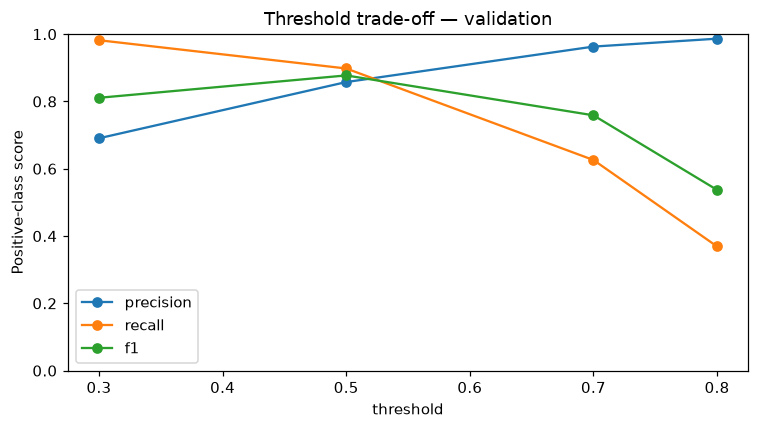


Nhận xét tham khảo: Tăng threshold làm ít review được dự đoán positive hơn: recall không tăng, precision có thể tăng nhưng không bảo đảm đơn điệu.


In [9]:
val_prob=baseline["clf"].predict_proba(baseline["x_validation"])[:,1]
threshold_rows=[{"threshold":t,**scores(validation.label,(val_prob>=t).astype(int))} for t in [.3,.5,.7,.8]]
table(threshold_rows)
dummy=DummyClassifier(strategy="most_frequent")
dummy.fit(np.zeros((len(train),1)),train.label)
dummy_validation=scores(validation.label,dummy.predict(np.zeros((len(validation),1))))
table([{"model":"Dummy most_frequent","split":"validation",**dummy_validation}])
pd.DataFrame(threshold_rows).set_index("threshold")[["precision","recall","f1"]].plot(marker="o",figsize=(7,4),ylim=(0,1))
plt.title("Threshold trade-off — validation");plt.ylabel("Positive-class score")
plt.tight_layout();plt.show()
note("Tăng threshold làm ít review được dự đoán positive hơn: recall không tăng, precision có thể tăng nhưng không bảo đảm đơn điệu.")

## 19. Evaluation — khóa model rồi mở test
Chọn cấu hình bằng **validation macro-F1**, tie-break theo tên model; không refit trên train+validation.
Các test metrics bên dưới dùng cùng 2.000 review để so sánh; không sử dụng kết quả test để đổi cấu hình.
Precision/Recall/F1 là positive-class; macro-F1 đánh giá trung bình hai lớp. Thời gian phụ thuộc máy, không phải benchmark phần cứng.

LOCKED selected model: TF-IDF uni+bigram uncapped + LR
Selection validation macro-F1: 0.8794088029071986


 seed                                model split representation classifier  feature_count  vocabulary_size  max_features ngrams stopwords   C  train_samples  validation_samples  test_samples  feature_fit_seconds  classifier_fit_seconds  training_seconds  accuracy  precision  recall     f1  macro_f1  tn  fp  fn  tp
 2026              TF-IDF unigram 10k + LR  test         TF-IDF         LR          10000            10000       10000.0      1      kept 1.0           6000                2000          2000               1.5449                  0.1191            1.6640    0.8740     0.8674   0.883 0.8751    0.8740 865 135 117 883
 2026                    Avg Word2Vec + LR  test   Avg Word2Vec         LR            100            26416           NaN    N/A      kept 1.0           6000                2000          2000              21.9739                  0.0899           22.0638    0.7970     0.8024   0.788 0.7952    0.7970 806 194 212 788
 2026             TF-IDF unigram 10k + SVM  test    

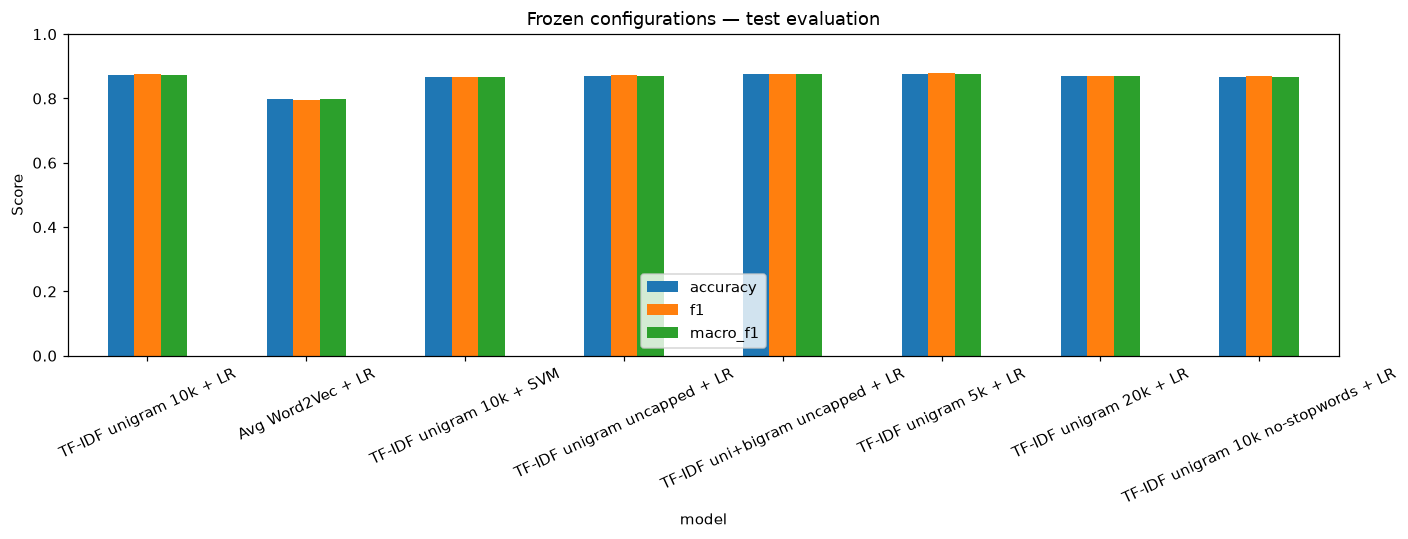


Nhận xét tham khảo: Cấu hình chọn từ validation: TF-IDF uni+bigram uncapped + LR; test accuracy=0.8755, F1=0.8768, macro-F1=0.8755. Một split/seed chưa đủ để khẳng định khác biệt nhỏ là có ý nghĩa thống kê.


In [10]:
validation_results=pd.DataFrame([result_row(m,"validation") for m in models.values()])
selection=validation_results.sort_values(["macro_f1","model"],ascending=[False,True]).iloc[0]
selected_name=selection["model"]
selected=models[selected_name]
print("LOCKED selected model:",selected_name)
print("Selection validation macro-F1:",selection["macro_f1"])
for m in models.values():
    evaluate_test(m,test)
test_results=pd.DataFrame([result_row(m,"test") for m in models.values()])
table(test_results)
dummy_test=scores(test.label,dummy.predict(np.zeros((len(test),1))))
table([{"model":"Dummy most_frequent","split":"test",**dummy_test}])
for m in [baseline,embedding,selected]:
    print("\nClassification report:",m["name"])
    print(classification_report(test.label,m["test_pred"],labels=[0,1],
          target_names=["negative","positive"],digits=4,zero_division=0))
test_results.set_index("model")[["accuracy","f1","macro_f1"]].plot.bar(figsize=(13,5),ylim=(0,1),rot=25)
plt.title("Frozen configurations — test evaluation");plt.ylabel("Score")
plt.tight_layout();plt.show()
note(f"Cấu hình chọn từ validation: {selected_name}; test accuracy={selected['test']['accuracy']:.4f}, "
     f"F1={selected['test']['f1']:.4f}, macro-F1={selected['test']['macro_f1']:.4f}. "
     "Một split/seed chưa đủ để khẳng định khác biệt nhỏ là có ý nghĩa thống kê.")

## 20. Confusion matrix
Hàng = actual; cột = predicted; thứ tự negative(0), positive(1):
TN/FP ở hàng negative; FN/TP ở hàng positive.
Confusion matrix của baseline, Avg Word2Vec và model đã chọn được in inline và lưu data/confusion_matrix.png theo đề.

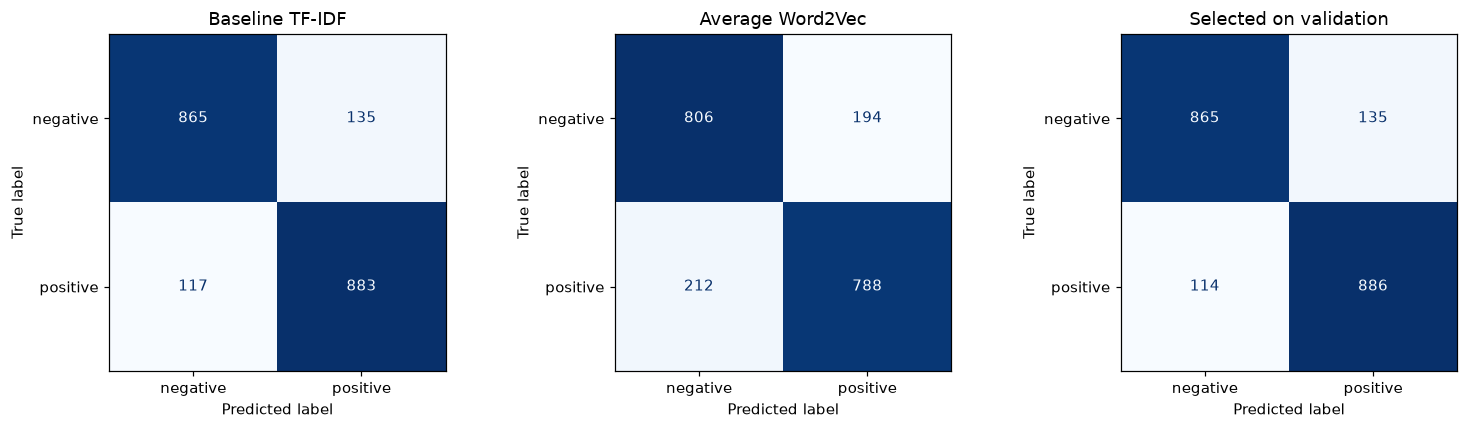

                          Model  False positive  False negative  Negative recall  Positive recall
        TF-IDF unigram 10k + LR             135             117            0.865            0.883
              Avg Word2Vec + LR             194             212            0.806            0.788
TF-IDF uni+bigram uncapped + LR             135             114            0.865            0.886

Nhận xét tham khảo: Model đã chọn có 135 false positive, nhiều hơn 114 false negative; positive precision phản ánh lỗi gán positive nhầm.


In [11]:
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,m,title in zip(axes,[baseline,embedding,selected],["Baseline TF-IDF","Average Word2Vec","Selected on validation"]):
    cm=confusion_matrix(test.label,m["test_pred"],labels=[0,1])
    ConfusionMatrixDisplay(cm,display_labels=["negative","positive"]).plot(ax=ax,colorbar=False,cmap="Blues")
    ax.set_title(title)
plt.tight_layout()
fig.savefig(ROOT/"data"/"confusion_matrix.png",dpi=170,bbox_inches="tight")
plt.show()
matrix_notes=[]
for m in [baseline,embedding,selected]:
    values=m["test"]
    matrix_notes.append({"Model":m["name"],"False positive":values["fp"],"False negative":values["fn"],
                         "Negative recall":values["tn"]/(values["tn"]+values["fp"]),
                         "Positive recall":values["recall"]})
table(matrix_notes)
s=selected["test"]
if s["fn"]>s["fp"]:
    note(f"Model đã chọn bỏ sót {s['fn']} positive, nhiều hơn {s['fp']} false positive; positive recall phản ánh lỗi bỏ sót.")
elif s["fp"]>s["fn"]:
    note(f"Model đã chọn có {s['fp']} false positive, nhiều hơn {s['fn']} false negative; positive precision phản ánh lỗi gán positive nhầm.")
else:
    note(f"Model đã chọn có FP=FN={s['fp']}; cần xem nội dung lỗi và recall từng lớp thay vì chỉ accuracy.")

## 22. Inspect model weights
Trọng số dương thúc đẩy positive, âm thúc đẩy negative; contribution thực tế còn phụ thuộc TF-IDF của review.
Top features chỉ học từ train. Giá trị lớn không chứng minh model hiểu ngữ nghĩa hay quan hệ nhân quả.

### Nhận xét trọng số — seed 2026
Top positive: great (+5.008), excellent (+3.393), wonderful (+3.004).
Top negative: bad (-5.020), worst (-4.915), awful (-3.677).
Các từ khen/chê có trọng số phù hợp sentiment; đóng góp thực tế còn phụ thuộc TF-IDF và ngữ cảnh review.

Direction   Feature  Weight
 positive     great  5.0080
 positive excellent  3.3931
 positive wonderful  3.0042
 positive      best  2.9955
 positive      very  2.7277
 positive      well  2.6752
 positive      will  2.5722
 positive   perfect  2.5239
 positive  favorite  2.4927
 positive      love  2.4875
 positive       fun  2.3647
 positive     loved  2.3571
 negative       bad -5.0198
 negative     worst -4.9148
 negative     awful -3.6772
 negative      poor -3.5833
 negative     waste -3.4713
 negative        no -2.9127
 negative      plot -2.9004
 negative    boring -2.8242
 negative     worse -2.7663
 negative   minutes -2.7608
 negative   nothing -2.7116
 negative    stupid -2.5519


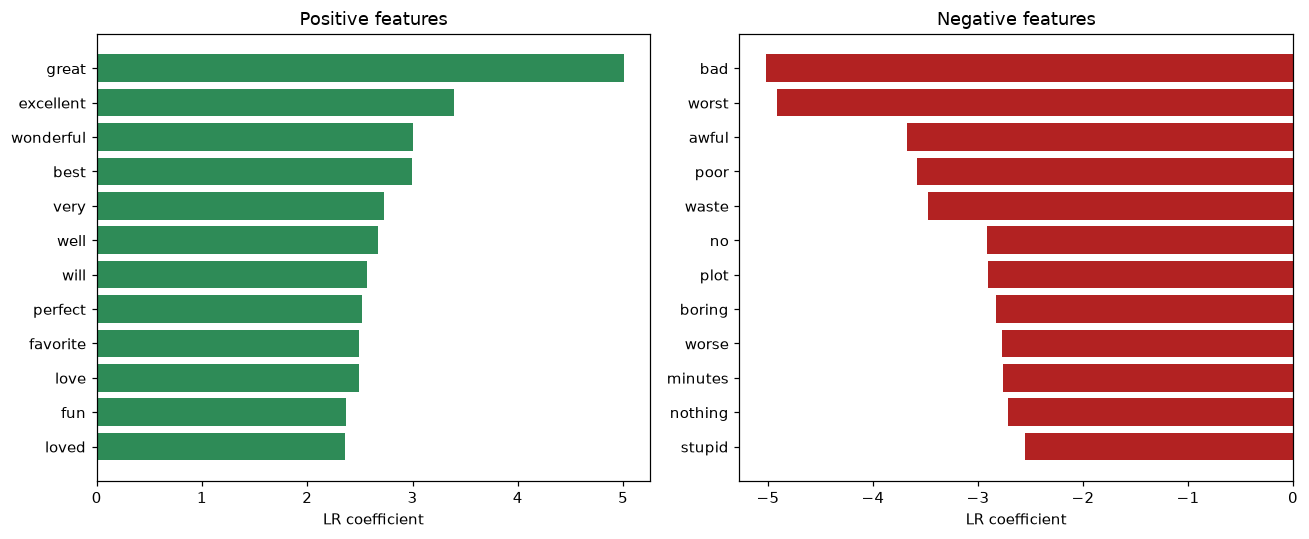


Nhận xét tham khảo: Đọc các từ trong bảng và đối chiếu review ở mục 21 để đánh giá tính phù hợp với sentiment. Tên diễn viên, thể loại hoặc tên phim có thể phản ánh bias dataset thay vì cảm xúc tổng quát.


In [12]:
vectorizer=baseline["vectorizer"]
names=vectorizer.get_feature_names_out()
weights=baseline["clf"].coef_[0]
positive_idx=np.argsort(-weights)[:12]
negative_idx=np.argsort(weights)[:12]
weight_rows=[{"Direction":direction,"Feature":names[i],"Weight":weights[i]}
             for direction,indices in [("positive",positive_idx),("negative",negative_idx)] for i in indices]
table(weight_rows)
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,idx,title,color in [(axes[0],positive_idx,"Positive features","seagreen"),
                           (axes[1],negative_idx,"Negative features","firebrick")]:
    ax.barh(names[idx][::-1],weights[idx][::-1],color=color)
    ax.set_title(title);ax.set_xlabel("LR coefficient")
plt.tight_layout();plt.show()
note("Đọc các từ trong bảng và đối chiếu review ở mục 21 để đánh giá tính phù hợp với sentiment. "
     "Tên diễn viên, thể loại hoặc tên phim có thể phản ánh bias dataset thay vì cảm xúc tổng quát.")

## 23. Application — Sentiment classification
Áp dụng model được khóa theo validation cho review mới. Các câu dưới đây là ví dụ minh họa do AI soạn, không phải benchmark độc lập.
Nếu model được chọn là SVM, báo decision score thay vì gọi đó là xác suất.

In [13]:
new_reviews=[
 "The acting is excellent and the story is moving. I loved this movie.",
 "The plot is boring and the acting is terrible. A waste of time.",
 "This movie is not good. I would not recommend it.",
 "The acting was good, but the confusing plot and dull ending ruined the film."
]
x_new=transform(selected,new_reviews)
new_pred=selected["clf"].predict(x_new)
new_scores=(selected["clf"].predict_proba(x_new)[:,1] if hasattr(selected["clf"],"predict_proba")
            else selected["clf"].decision_function(x_new))
table([{"Review":text,"Prediction":LABELS[int(pred)],"P(positive)" if hasattr(selected["clf"],"predict_proba") else "Decision score":value}
       for text,pred,value in zip(new_reviews,new_pred,new_scores)])
note("Không đánh giá tổng quát hóa bằng bốn câu tự soạn. Sentence-level probe có thể lệch miền so với full IMDb reviews.")

                                                                      Review Prediction  P(positive)
        The acting is excellent and the story is moving. I loved this movie.   positive       0.8446
             The plot is boring and the acting is terrible. A waste of time.   negative       0.0324
                           This movie is not good. I would not recommend it.   negative       0.3605
The acting was good, but the confusing plot and dull ending ruined the film.   negative       0.2110

Nhận xét tham khảo: Không đánh giá tổng quát hóa bằng bốn câu tự soạn. Sentence-level probe có thể lệch miền so với full IMDb reviews.


## 24. AI assistance statement
- Tool: Codex.
- Purpose: triển khai preprocessing, classifier, visualization, thực nghiệm và bản nháp tài liệu.
- Generated: preprocessing.py, classification.py, notebook, kết quả chạy, draft calculation/discussion/error analysis/reflection.
- Modified: sinh viên bổ sung phần thực tế đã chỉnh.
- Verified: các output thực nghiệm đã chạy và in trong notebook; sinh viên cần tự kiểm tra nhận xét.




## 25. Deliverables
README.md, Calculations.pdf, Prediction.pdf, classification.ipynb, preprocessing.py, results.csv,
data/confusion_matrix.png, Error_analysis.pdf, Reflection.pdf.
Có thêm classification.py, run_notebook.py, requirements.txt và dataset subset để chạy lại.

In [14]:

if "example_rows" not in globals():
    example_rows=[]
    error_doc=["# Error analysis — bản nháp tham khảo",
        f"Baseline TF-IDF unigram 10k + LR; seed={SEED}; threshold=0.5.",
        "Ví dụ được cập nhật theo lần chạy mới. Sinh viên tự đọc và xác nhận nguyên nhân."]
    for number,i in enumerate(select_examples(baseline,test),1):
        row=test.iloc[i]
        pred=int(baseline["test_pred"][i])
        words=tokenize(row.text)
        oov=sum(w not in baseline["vectorizer"].vocabulary_ for w in words)/len(words) if words else 0
        correct=pred==int(row.label)
        contributions=feature_contributions(baseline,row.text,8)
        category="Phù hợp nhãn" if correct else ("Negation cần kiểm tra" if "not" in words else "Lexical ambiguity / short text — giả thuyết")
        example_rows.append({"Seed":SEED,"Case":number,"ID":row.id,"True":LABELS[int(row.label)],
            "Predicted":LABELS[pred],"Correct":correct,"P(positive)":baseline["test_probability"][i],
            "Tokens":len(words),"OOV fraction":oov,"Category":category})
        error_doc.extend([f"## Ví dụ {number} — {'Đúng' if correct else 'Sai'}",
            f"- ID: {row.id}; true={LABELS[int(row.label)]}; predicted={LABELS[pred]}; P(positive)={baseline['test_probability'][i]:.4f}.",
            f"- Tokens: {len(words)}; OOV fraction: {oov:.4f}; category: {category}.",
            "### Văn bản\n\n"+row.text,
            "### Dẫn chứng feature\n\n"+contributions.round(4).to_string(index=False),
            "### Nhận xét tham khảo\n\nĐóng góp dương đẩy dự đoán về positive, âm đẩy về negative. "
            +("Dự đoán phù hợp nhãn, nhưng cần kiểm tra lời khen/chê trong câu." if correct else
              "Cần đối chiếu full review với feature contributions; presence của not hoặc từ hiếm chưa chứng minh nguyên nhân lỗi.")])

results=pd.concat([validation_results,test_results],ignore_index=True)
dummy_rows=[{"seed":SEED,"model":"Dummy most_frequent","split":split,"representation":"None","classifier":"Dummy",
    "train_samples":len(train),"validation_samples":len(validation),"test_samples":len(test),
    **values} for split,values in [("validation",dummy_validation),("test",dummy_test)]]
results=pd.concat([results,pd.DataFrame(dummy_rows)],ignore_index=True)
test_predictions=pd.DataFrame({"id":test.id,"true_label":test.label})
for m in models.values():
    test_predictions[m["name"]]=m["test_pred"]

metric_rows=len(results)
results=pd.concat([
    results.assign(record_type="evaluation"),
    pd.DataFrame(example_rows).assign(record_type="error_analysis"),
    pd.DataFrame(threshold_rows).assign(record_type="threshold"),
    pd.DataFrame(weight_rows).assign(record_type="model_weight"),
    test_predictions.assign(record_type="test_prediction")
],ignore_index=True,sort=False)
results=results[["record_type"]+[column for column in results.columns if column!="record_type"]]
results.to_csv(ROOT/"results.csv",index=False,encoding="utf-8-sig")

summary={"seed":SEED,"selected_model":selected_name,"selection_metric":"validation macro-F1",
         "train_samples":len(train),"validation_samples":len(validation),"test_samples":len(test),
         "model_count":len(models),"metric_rows":metric_rows,"results_rows":len(results),
         "record_counts":results.record_type.value_counts().to_dict(),
         "selected_validation":selected["validation"],"selected_test":selected["test"]}
(ROOT/"run_summary.json").write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding="utf-8")
print("Saved results.csv:",len(results),"rows.")
print(results.record_type.value_counts().to_string())
print("Selected:",selected_name)
print("Plots are inline; required data/confusion_matrix.png is also saved.")

Saved results.csv: 2052 rows.
evaluation: 18
error_analysis: 6
threshold: 4
model_weight: 24
test_prediction: 2000
Selected: TF-IDF uni+bigram uncapped + LR
Plots are inline; required data/confusion_matrix.png is also saved.
